# 2026 KBO 가을야구 — 어느 팀의 우승 확률이 가장 높을까

**기준: 2026년 10월 15일** (정규시즌 종료, 와일드카드 결정전 LG 4-1 두산 승리 반영)

정규시즌 득점·실점으로 각 팀의 실력을 추정하고, 실제 포스트시즌 대진·경기 수·홈 배정을 그대로 넣어 우승 확률을 계산합니다.

| 단계 | 대진 | 방식 | 홈 배정 |
|---|---|---|---|
| 준플레이오프 | 3위 KIA vs 4위 LG | 5전 3선승 | 1·2·5차전 KIA |
| 플레이오프 | 2위 삼성 vs 준PO 승자 | 5전 3선승 | 1·2·5차전 삼성 |
| 한국시리즈 | 1위 KT vs PO 승자 | 7전 4선승 | 1·2·6·7차전 KT |

In [1]:
import pandas as pd, numpy as np, functools
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # macOS는 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/kbo_2026_regular_season.csv')
df['wpct'] = df.W / (df.W + df.L)          # KBO 승률: 무승부 제외
home_wpct = df.home_W.sum() / (df.home_W.sum() + df.home_L.sum())
HOME_EDGE = home_wpct - 0.5
print(f'2026 리그 홈 승률 {home_wpct:.3f} -> 홈 이점 +{HOME_EDGE:.3f}')
df[['team', 'W', 'L', 'T', 'wpct', 'R', 'RA']]

2026 리그 홈 승률 0.515 -> 홈 이점 +0.015


,team,W,L,T,wpct,R,RA
0,KT,90,49,5,0.647482,825,649
1,삼성,83,58,3,0.588652,806,669
2,KIA,79,63,2,0.556338,769,664
3,LG,78,65,1,0.545455,723,726
4,두산,73,66,5,0.525180,688,630
5,SSG,65,74,5,0.467626,706,797
6,롯데,64,77,3,0.453901,679,742
7,NC,64,78,2,0.450704,719,772
8,한화,57,83,4,0.407143,821,835
9,키움,50,90,4,0.357143,565,817


## 1. 팀 실력 추정 — 피타고리안 승률

승패에는 운(접전 결과)이 많이 섞이므로, 득점·실점으로 계산한 **피타고리안 승률**을 실력으로 씁니다. 지수 k는 2026 KBO 10개 팀 기록에 가장 잘 맞는 값을 찾습니다.

In [2]:
ks = np.arange(1.4, 2.6, 0.01)
err = [np.sqrt(np.mean((df.R**k / (df.R**k + df.RA**k) - df.wpct)**2)) for k in ks]
K = round(float(ks[int(np.argmin(err))]), 2)
df['pyth'] = df.R**K / (df.R**K + df.RA**K)
df['luck_wins'] = (df.wpct - df.pyth) * (df.W + df.L)   # 실제 승수 - 기대 승수
print(f'최적 지수 k = {K}  (144경기 기준 오차 ±{min(err)*144:.1f}승)')
df[['team', 'wpct', 'pyth', 'luck_wins']].round(3)

최적 지수 k = 1.84  (144경기 기준 오차 ±5.1승)


,team,wpct,pyth,luck_wins
0,KT,0.647,0.609,5.402
1,삼성,0.589,0.585,0.534
2,KIA,0.556,0.567,-1.532
3,LG,0.545,0.498,6.772
4,두산,0.525,0.540,-2.119
5,SSG,0.468,0.444,3.220
6,롯데,0.454,0.459,-0.758
7,NC,0.451,0.467,-2.361
8,한화,0.407,0.492,-11.911
9,키움,0.357,0.337,2.880


**읽는 법**: `luck_wins`가 +이면 득실점에 비해 더 많이 이긴 팀입니다. **LG는 득실차가 −3인데 78승(기대보다 약 +7승)**을 거둬, 실력에 비해 운이 많이 따른 팀으로 보입니다. 반대로 두산은 득실차 +58로 실력은 4위급이었지만 와일드카드에서 탈락했습니다.

In [3]:
playoff = ['KT', '삼성', 'KIA', 'LG']
S_PYTH = dict(zip(df.team, df.pyth)); S_WPCT = dict(zip(df.team, df.wpct))

def log5(a, b):
    # 승률 a인 팀이 승률 b인 팀을 이길 확률 (빌 제임스의 Log5)
    return (a - a*b) / (a + b - 2*a*b)

def game_prob(S, a, b, a_home):
    p = log5(S[a], S[b]) + (HOME_EDGE if a_home else -HOME_EDGE)
    return min(max(p, 0), 1)

H5 = (True, True, False, False, True)                    # 상위 시드 기준 홈 여부
H7 = (True, True, False, False, False, True, True)

def series_prob(S, a, b, need, homes):
    # a(상위 시드)가 시리즈를 이길 정확한 확률 (재귀)
    @functools.lru_cache(None)
    def rec(i, wa, wb):
        if wa == need: return 1.0
        if wb == need: return 0.0
        p = game_prob(S, a, b, homes[i])
        return p * rec(i+1, wa+1, wb) + (1-p) * rec(i+1, wa, wb+1)
    return rec(0, 0, 0)

def bracket(S):
    stage = {t: {'PO 진출': 0.0, 'KS 진출': 0.0, '우승': 0.0} for t in playoff}
    stage['KT']['PO 진출'] = stage['KT']['KS 진출'] = 1.0; stage['삼성']['PO 진출'] = 1.0
    p_kia = series_prob(S, 'KIA', 'LG', 3, H5)
    for semi, ps in [('KIA', p_kia), ('LG', 1 - p_kia)]:
        stage[semi]['PO 진출'] += ps
        p_sam = series_prob(S, '삼성', semi, 3, H5)
        for po, pq in [('삼성', p_sam), (semi, 1 - p_sam)]:
            stage[po]['KS 진출'] += ps * pq
            p_kt = series_prob(S, 'KT', po, 4, H7)
            stage['KT']['우승'] += ps * pq * p_kt
            stage[po]['우승'] += ps * pq * (1 - p_kt)
    return pd.DataFrame(stage).T

res = bracket(S_PYTH)
print(res.round(3))

     PO 진출  KS 진출     우승
KT   1.000  1.000  0.591
삼성   1.000  0.585  0.259
KIA  0.633  0.291  0.117
LG   0.367  0.123  0.033


## 2. 시뮬레이션으로 한 번 더 확인

위 값은 확률을 정확히 계산한 결과입니다. 같은 모델로 가을야구를 **10만 번** 굴려 봐서 결과가 맞는지 검증합니다.

In [4]:
rng = np.random.default_rng(2026)
def play(S, a, b, need, homes):
    wa = wb = 0; i = 0
    while wa < need and wb < need:
        if rng.random() < game_prob(S, a, b, homes[i]): wa += 1
        else: wb += 1
        i += 1
    return a if wa == need else b

N = 100_000; wins = {t: 0 for t in playoff}
for _ in range(N):
    semi = play(S_PYTH, 'KIA', 'LG', 3, H5)
    po = play(S_PYTH, '삼성', semi, 3, H5)
    wins[play(S_PYTH, 'KT', po, 4, H7)] += 1
sim = pd.Series({t: wins[t] / N for t in playoff})
print(pd.DataFrame({'정확 계산': res['우승'], f'시뮬레이션 {N:,}회': sim}).round(3))

     정확 계산  시뮬레이션 100,000회
KT   0.591           0.590
삼성   0.259           0.259
KIA  0.117           0.119
LG   0.033           0.032


## 3. 모델을 바꾸면? — 실제 승률 기준과 비교

실력을 득실점(피타고리안) 대신 **실제 승률**로 넣으면 결과가 어떻게 달라지는지 봅니다.

     득실점 기반 (기본)  실제 승률 기반
KT         0.591     0.670
삼성         0.259     0.209
KIA        0.117     0.068
LG         0.033     0.054


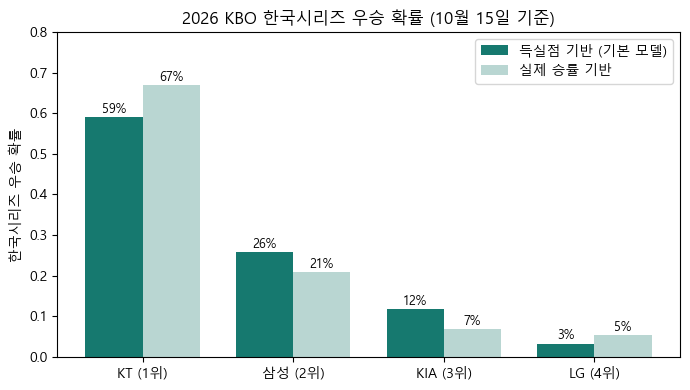

In [5]:
res_w = bracket(S_WPCT)
cmp = pd.DataFrame({'득실점 기반 (기본)': res['우승'], '실제 승률 기반': res_w['우승']}).loc[playoff]
print(cmp.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(playoff)); w = 0.38
b1 = ax.bar(x - w/2, cmp.iloc[:, 0], w, label='득실점 기반 (기본 모델)', color='#16796f')
b2 = ax.bar(x + w/2, cmp.iloc[:, 1], w, label='실제 승률 기반', color='#b9d6d2')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f'{b.get_height():.0%}', ha='center', fontsize=9)
ax.set_xticks(x, ['KT (1위)', '삼성 (2위)', 'KIA (3위)', 'LG (4위)'])
ax.set_ylim(0, 0.8); ax.set_ylabel('한국시리즈 우승 확률')
ax.set_title('2026 KBO 한국시리즈 우승 확률 (10월 15일 기준)')
ax.legend(); plt.tight_layout(); plt.savefig('images/01_champion_prob.png', dpi=150); plt.show()

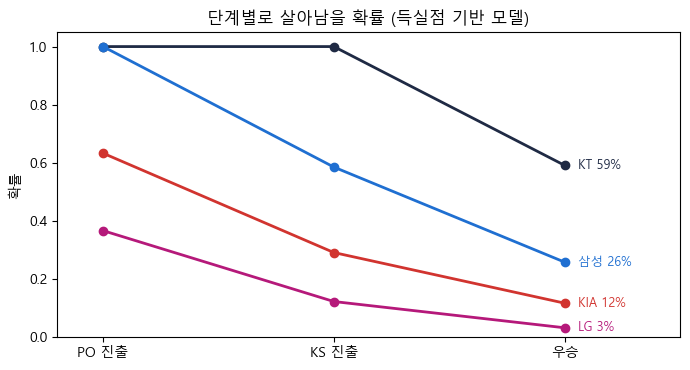

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = ['PO 진출', 'KS 진출', '우승']
colors = {'KT': '#1f2a44', '삼성': '#1f6fd1', 'KIA': '#d1342f', 'LG': '#b5197a'}
for t in playoff:
    ax.plot(order, [res.loc[t, o] for o in order], marker='o', lw=2, color=colors[t])
    ax.text(2.06, res.loc[t, '우승'], f"{t} {res.loc[t, '우승']:.0%}", va='center', color=colors[t], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_xlim(-0.2, 2.5); ax.set_ylabel('확률')
ax.set_title('단계별로 살아남을 확률 (득실점 기반 모델)')
plt.tight_layout(); plt.savefig('images/02_stage_prob.png', dpi=150); plt.show()

## 정리

- **KT가 가장 유력합니다 (약 59%)**. 득실차 +176으로 실력 자체가 가장 높고, 한국시리즈에 직행해 7경기 중 4경기를 홈에서 치릅니다.
- **삼성이 2순위 (약 26%)**. 실력은 KT와 거의 비슷하지만(피타고리안 .584 vs .608), 플레이오프를 한 번 더 이겨야 합니다.
- **KIA는 준PO에서 LG를 이길 확률이 약 63%**입니다. LG는 득실차가 −3이라 득실점 모델에서는 실력이 .500 수준으로 평가됩니다.
- 실제 승률로 바꾸면 KT 확률이 67%까지 올라가고, LG가 KIA와 비슷해집니다. **어느 모델이든 KT 우세라는 결론은 같습니다.**

**한계**
- 단기전에서 중요한 선발 로테이션(에이스 등판 순서), 부상, 휴식일 효과는 넣지 않았습니다
- 팀 실력은 시즌 전체 평균이라 최근 흐름(KT 마지막 10경기 9승 1무, 삼성 4승 6패)은 반영하지 않았습니다
- 포스트시즌 무승부(연장 제한)는 없다고 가정했습니다

데이터 출처: [스탯티즈 팀 순위](https://www.statiz.co.kr/) · [KBO 대시보드](https://kbo-dashboard.co.kr/standings/) (2026년 10월 12일 정규시즌 종료 기준), 와일드카드 결과 [일간스포츠](https://isplus.com/article/view/isp202610140257)